# HS524M Test 2, Question 2 — Kolkata NO₂ and women aged 15–49 (2020)

**Question:** What share of women aged 15–49 reside in the highest quartile of satellite-observed annual tropospheric NO₂ within the Kolkata study boundary?

Run cells in order. The notebook creates an annual map, a high-NO₂ population map, a 12-month GIF, CSV summaries and a ready-to-host `index.html` in one output folder. The webpage assets use embedded raster overlays and a relative GIF link; upload the **entire output folder**, preserving filenames. An internet connection is required for the basemap and Leaflet controls. Replace the Google Earth Engine project ID below if necessary and complete Earth Engine authentication when prompted.

**Scope:** This answers Question 2, row 2. Question 1 requires your QField waste-bin observations and photos, which were not provided here.

In [1]:
# Run once if packages are not installed, then restart the kernel if prompted.
%pip install -q earthengine-api geemap folium pandas pillow requests

Note: you may need to restart the kernel to use updated packages.


In [10]:
from pathlib import Path
from datetime import date
from calendar import month_name
from html import escape
import base64
import io
import json

import ee
import folium
import geemap
import pandas as pd
import requests
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Image as NotebookImage

EE_PROJECT = "urban-sem-iii"  # replace with your registered EE-enabled Cloud project
OUTPUT_DIR = Path.cwd() / "kolkata_no2_web"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
YEAR = 2020
START, END = "2020-01-01", "2021-01-01"
NO2_BAND = "tropospheric_NO2_column_number_density"
SCALE_NO2 = 1113  # approximate S5P catalog pixel size in metres
NO2_VIS = {"min": 0, "max": 0.0002,
           "palette": ["253494", "2c7fb8", "41b6c4", "a1dab4", "ffffcc", "fe9929", "cc4c02"]}

try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    print("Earth Engine authentication is required in this environment.")
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
print("Earth Engine initialized. Outputs:", OUTPUT_DIR)

Earth Engine initialized. Outputs: C:\Users\jrana\Desktop\urban(sem 3)\kolkata_no2_web


## 1. Boundary and sources

The boundary is the **Kolkata ADM2 district polygon from FAO GAUL 2015 level 2**, which can differ from the Kolkata Municipal Corporation area. This choice defines the denominator and all maps; it must be stated on the webpage. Sources: [GAUL 2015](https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2), [Sentinel-5P OFFL NO₂](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S5P_OFFL_L3_NO2), [WorldPop 2020 age–sex](https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop_age_sex).

In [3]:
city = (ee.FeatureCollection("FAO/GAUL/2015/level2")
        .filter(ee.Filter.eq("ADM0_NAME", "India"))
        .filter(ee.Filter.eq("ADM1_NAME", "West Bengal"))
        .filter(ee.Filter.eq("ADM2_NAME", "Kolkata")))
city_count = city.size().getInfo()
if city_count != 1:
    raise ValueError(f"Expected one GAUL Kolkata feature; got {city_count}. Inspect GAUL names.")
region = city.geometry()
geojson = city.getInfo()
coords = region.bounds(maxError=1).coordinates().getInfo()[0]
west, east = min(p[0] for p in coords), max(p[0] for p in coords)
south, north = min(p[1] for p in coords), max(p[1] for p in coords)
map_bounds = [[south, west], [north, east]]
print(f"GAUL district area: {region.area(maxError=1).divide(1e6).getInfo():.1f} km²")

C:\Users\jrana\miniconda3\envs\uisa_2026\Lib\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


GAUL district area: 91.8 km²


## 2. Annual and monthly NO₂

Filter each source image by cloud fraction ≤0.30, then average valid NO₂ observations. The source catalog already applies a retrieval validity filter to NO₂. The 75th percentile uses the annual **NO₂ pixel distribution within the selected district**, at the native S5P grid and an approximately 1.1 km analysis scale. Its threshold is relative to Kolkata in 2020, not a health standard. Monthly composites use exactly the same visual scale as the annual composite.

In [4]:
source = (ee.ImageCollection("COPERNICUS/S5P/OFFL/L3_NO2")
          .filterDate(START, END).filterBounds(region))
source_count = source.size().getInfo()
if source_count == 0:
    raise ValueError("No Sentinel-5P images intersect the study area in 2020.")

def mask_cloud(image):
    return (image.select(NO2_BAND)
            .updateMask(image.select("cloud_fraction").lte(0.30))
            .copyProperties(image, ["system:time_start"]))

no2 = source.map(mask_cloud)
# Collection means otherwise have a generic 1-degree default projection.
no2_projection = ee.Image(no2.first()).select(NO2_BAND).projection()
annual = (no2.mean().rename("NO2")
          .setDefaultProjection(no2_projection).clip(region))
annual_stats = annual.reduceRegion(
    reducer=ee.Reducer.mean().combine(ee.Reducer.percentile([75]), sharedInputs=True),
    geometry=region, crs=no2_projection, scale=SCALE_NO2,
    maxPixels=1e9, tileScale=4).getInfo()
print("Annual statistics:", annual_stats)
annual_mean = annual_stats.get("NO2_mean")
q75 = annual_stats.get("NO2_p75")
if annual_mean is None or q75 is None:
    raise ValueError("Missing annual NO₂ statistics; inspect image coverage and reduceRegion output.")
print(f"Annual city mean: {annual_mean:.8f} mol/m²; pixelwise 75th percentile: {q75:.8f} mol/m²")
high_mask = annual.gte(ee.Number(q75)).And(annual.mask()).rename("high_no2")

monthly_images, monthly_rows = [], []
for month in range(1, 13):
    d0 = date(YEAR, month, 1)
    d1 = date(YEAR + (month == 12), month % 12 + 1, 1)
    subset = no2.filterDate(d0.isoformat(), d1.isoformat())
    n = subset.size().getInfo()
    if n == 0:
        monthly_rows.append({"Month": month_name[month], "Images": n, "Mean_NO2_mol_m2": None})
        continue
    image = subset.mean().rename("NO2").setDefaultProjection(no2_projection).clip(region)
    value = image.reduceRegion(ee.Reducer.mean(), region, crs=no2_projection,
                               scale=SCALE_NO2, maxPixels=1e9, tileScale=4).get("NO2").getInfo()
    monthly_rows.append({"Month": month_name[month], "Images": n, "Mean_NO2_mol_m2": value})
    if value is not None:
        monthly_images.append((month, image))
monthly_df = pd.DataFrame(monthly_rows)
monthly_df.to_csv(OUTPUT_DIR / "kolkata_monthly_no2_2020.csv", index=False)
display(monthly_df)
if len(monthly_images) < 2:
    raise ValueError("Fewer than two valid monthly composites; cannot make a meaningful GIF.")

Annual statistics: {'NO2_mean': 8.349077134757768e-05, 'NO2_p75': 8.689957516570357e-05}
Annual city mean: 0.00008349 mol/m²; pixelwise 75th percentile: 0.00008690 mol/m²


,Month,Images,Mean_NO2_mol_m2
0,January,439,0.000128
1,February,407,0.000113
2,March,440,0.000072
3,April,425,0.000052
4,May,438,0.000046
5,June,425,0.000057
6,July,439,0.000039
7,August,437,0.000046
8,September,425,0.000042
9,October,440,0.000055


## 3. Population residing in relatively high NO₂ areas

WorldPop age bins `F_15` through `F_45` cover ages 15–49. A coarse Sentinel-5P class is assigned by **nearest neighbour to the centres of WorldPop cells**; the finer cells do not reveal subpixel NO₂ variation. Population totals are summed on the native WorldPop grid within GAUL Kolkata. The exposure share uses **all estimated women aged 15–49 in that district** as denominator. Missing NO₂ coverage remains outside the high group and is separately reported.

In [5]:
worldpop_collection = (ee.ImageCollection("WorldPop/GP/100m/pop_age_sex")
                       .filter(ee.Filter.eq("country", "IND"))
                       .filter(ee.Filter.eq("year", 2020)))
worldpop_count = worldpop_collection.size().getInfo()
if worldpop_count != 1:
    # Verify the catalog asset itself if its metadata differs from the expected country code.
    print("Filtered WorldPop count:", worldpop_count)
    candidate = ee.Image("WorldPop/GP/100m/pop_age_sex/IND_2020")
    print("Candidate properties:", candidate.toDictionary(["country", "year", "system:index"]).getInfo())
    worldpop = candidate
else:
    worldpop = ee.Image(worldpop_collection.first())

female_bands = [f"F_{a}" for a in range(15, 50, 5)]
missing = set(female_bands) - set(worldpop.bandNames().getInfo())
if missing:
    raise ValueError(f"Required WorldPop bands are missing: {sorted(missing)}")
women = worldpop.select(female_bands).reduce(ee.Reducer.sum()).rename("women_15_49")
pop_projection = worldpop.select("F_15").projection()
pop_scale = pop_projection.nominalScale().getInfo()

# Explicit nearest-neighbour reprojection of the coarser class to the population grid.
high_on_pop_grid = high_mask.reproject(pop_projection)
valid_on_pop_grid = annual.mask().reproject(pop_projection)
exposed_image = women.updateMask(high_on_pop_grid).rename("exposed_women")
valid_women_image = women.updateMask(valid_on_pop_grid).rename("women_valid_no2")
combined = (women.addBands(exposed_image).addBands(valid_women_image))
counts = combined.reduceRegion(reducer=ee.Reducer.sum(), geometry=region,
                               crs=pop_projection, scale=pop_scale,
                               maxPixels=1e10, tileScale=8).getInfo()
total_women = counts.get("women_15_49")
exposed_women = counts.get("exposed_women") or 0
valid_women = counts.get("women_valid_no2") or 0
if total_women is None or total_women <= 0:
    raise ValueError(f"Invalid WorldPop sum: {counts}")
share = 100 * exposed_women / total_women
coverage_share = 100 * valid_women / total_women
if exposed_women > total_women + 1e-6:
    raise AssertionError("Exposed population exceeds district total; inspect grid alignment.")

summary = pd.DataFrame([
    ("Study area", "FAO GAUL 2015 ADM2 Kolkata district"),
    ("Year", YEAR),
    ("Annual city mean NO₂ (mol/m²)", f"{annual_mean:.8f}"),
    ("High NO₂ threshold, pixel 75th percentile (mol/m²)", f"{q75:.8f}"),
    ("Women aged 15–49, district (WorldPop estimate)", round(total_women)),
    ("Women aged 15–49 in high NO₂ cells (estimate)", round(exposed_women)),
    ("Exposure share of all district women aged 15–49 (%)", f"{share:.2f}"),
    ("Women with valid annual NO₂ data (%)", f"{coverage_share:.2f}"),
], columns=["Indicator", "Value"])
summary.to_csv(OUTPUT_DIR / "kolkata_women_no2_exposure_2020.csv", index=False)
display(summary)

,Indicator,Value
0,Study area,FAO GAUL 2015 ADM2 Kolkata district
1,Year,2020
2,Annual city mean NO₂ (mol/m²),0.00008349
3,"High NO₂ threshold, pixel 75th percentile (mol...",0.00008690
4,"Women aged 15–49, district (WorldPop estimate)",821208
5,Women aged 15–49 in high NO₂ cells (estimate),177843
6,Exposure share of all district women aged 15–4...,21.66
7,Women with valid annual NO₂ data (%),100.00


## 4. Portable maps and GIF

These output maps embed their NO₂ image overlays and boundary geometry in the HTML. The 12 monthly map frames form the required animated GIF; no separate monthly graph is produced. They therefore do not depend on temporary Earth Engine map tiles after upload. The OpenStreetMap basemap and Leaflet scripts still require normal internet access. Each frame uses the same 0–0.0002 mol/m² scale; values above that limit saturate on the display only. Numeric statistics use the original, unclamped data.

Map saved: C:\Users\jrana\Desktop\urban(sem 3)\kolkata_no2_web\kolkata_annual_no2_2020.html



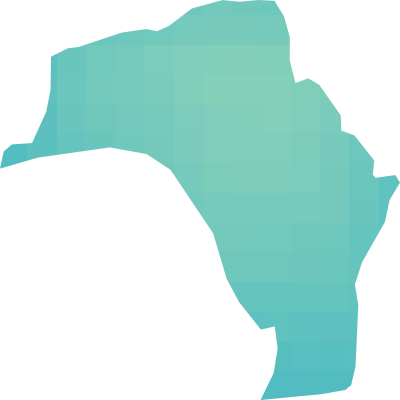

Map saved: C:\Users\jrana\Desktop\urban(sem 3)\kolkata_no2_web\kolkata_women_high_no2_2020.html



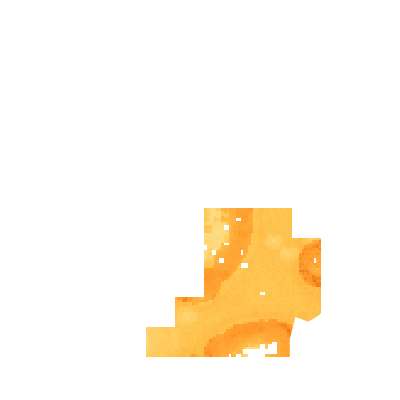

Both maps have been created.


In [7]:

import io
import time
import base64
import requests
import ee
import geemap
import folium
from PIL import Image
from IPython.display import display

# --------------------------------------------------
# 1. Set the common map region
# --------------------------------------------------
thumb_region = ee.Geometry.Rectangle(
    [west, south, east, north],
    proj="EPSG:4326",
    geodesic=False
)

map_bounds = [[south, west], [north, east]]

# --------------------------------------------------
# 2. Download Earth Engine thumbnail with retries
# --------------------------------------------------
def png_bytes(image, vis, attempts=3):

    url = image.visualize(**vis).getThumbURL({
        "region": thumb_region,
        "dimensions": "400x400",
        "format": "png"
    })

    last_error = None

    for attempt in range(attempts):
        try:
            response = requests.get(
                url,
                timeout=(30, 180)
            )
            response.raise_for_status()

            result = Image.open(
                io.BytesIO(response.content)
            ).convert("RGBA")

            output = io.BytesIO()
            result.save(output, format="PNG")

            return output.getvalue()

        except requests.exceptions.RequestException as error:
            last_error = error
            print(
                f"Download attempt {attempt + 1} failed: {error}"
            )

            if attempt < attempts - 1:
                time.sleep(5)

    raise RuntimeError(
        "Earth Engine thumbnail failed after three attempts. "
        "Check your internet connection and try again."
    ) from last_error

# --------------------------------------------------
# 3. Create interactive HTML map with legend
# --------------------------------------------------
def overlay_map(raster_bytes, name, out_file, legend_html):

    m = folium.Map(
        location=[(south + north) / 2, (west + east) / 2],
        zoom_start=11,
        tiles="OpenStreetMap",
        control_scale=True
    )

    data_url = (
        "data:image/png;base64,"
        + base64.b64encode(raster_bytes).decode("ascii")
    )

    folium.raster_layers.ImageOverlay(
        image=data_url,
        bounds=map_bounds,
        name=name,
        overlay=True,
        opacity=0.82,
        interactive=False
    ).add_to(m)

    folium.GeoJson(
        geojson,
        name="Kolkata boundary",
        style_function=lambda feature: {
            "color": "#111111",
            "weight": 2,
            "fillOpacity": 0
        }
    ).add_to(m)

    folium.LayerControl(collapsed=False).add_to(m)
    m.fit_bounds(map_bounds)
    m.get_root().html.add_child(
        folium.Element(legend_html)
    )

    output_path = OUTPUT_DIR / out_file
    m.save(str(output_path))

    print("Map saved:", output_path)
    return m

# --------------------------------------------------
# 4. Annual mean tropospheric NO2 map, 2020
# --------------------------------------------------
NO2_VIS = {
    "min": 0,
    "max": 0.0002,
    "palette": [
        "253494", "2c7fb8", "41b6c4",
        "a1dab4", "ffffcc", "fe9929", "cc4c02"
    ]
}

annual_png = png_bytes(annual, NO2_VIS)

(OUTPUT_DIR / "annual_no2.png").write_bytes(annual_png)

legend = """
<div style="position:fixed;bottom:25px;left:25px;
z-index:9999;background:white;padding:12px;
border:1px solid #999;font:13px Arial;max-width:270px">
<b>Kolkata Annual Mean Tropospheric NO₂ — 2020</b><br>
Unit: mol/m²<br>
<div style="background:linear-gradient(90deg,#253494,#2c7fb8,
#41b6c4,#a1dab4,#ffffcc,#fe9929,#cc4c02);
height:12px;margin:6px 0"></div>
0 &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; 0.0002
</div>
"""

annual_map = overlay_map(
    annual_png,
    "2020 Annual Mean NO2",
    "kolkata_annual_no2_2020.html",
    legend
)

display(annual_map)

# --------------------------------------------------
# 5. Women aged 15–49 in high-NO2 cells
# --------------------------------------------------
exposure_vis = {
    "min": 0,
    "max": 200,
    "palette": [
        "fff7bc", "fec44f", "fe9929",
        "cc4c02", "800026"
    ]
}

exposure_png = png_bytes(
    exposed_image.clip(region),
    exposure_vis
)

(OUTPUT_DIR / "women_high_no2.png").write_bytes(
    exposure_png
)

exposure_legend = f"""
<div style="position:fixed;bottom:25px;left:25px;
z-index:9999;background:white;padding:12px;
border:1px solid #999;font:13px Arial;max-width:285px">
<b>Women Aged 15–49 in High-NO₂ Cells</b><br>
WorldPop estimated people per ~100 m cell<br>
<div style="background:linear-gradient(90deg,#fff7bc,#fec44f,
#fe9929,#cc4c02,#800026);
height:12px;margin:6px 0"></div>
0 &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; ≥200<br>
High NO₂ threshold: {q75:.8f} mol/m²<br>
Transparent areas: outside high class or no data
</div>
"""

exposure_map = overlay_map(
    exposure_png,
    "Women in High NO2 Cells",
    "kolkata_women_high_no2_2020.html",
    exposure_legend
)

display(exposure_map)

print("Both maps have been created.")


Animated GIF saved: C:\Users\jrana\Desktop\urban(sem 3)\kolkata_no2_web\kolkata_monthly_no2_2020.gif (12 monthly frames)


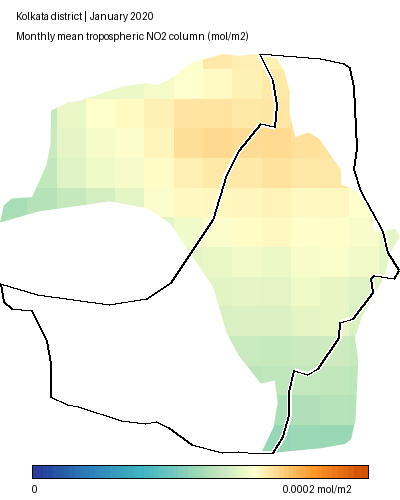

In [8]:
# All frames use the same bounds, palette and display range. The raster is
# rendered on white, with the GAUL district outline and a fixed colour legend.
gif_frames = []
font = ImageFont.load_default()
palette = ["253494", "2c7fb8", "41b6c4", "a1dab4", "ffffcc", "fe9929", "cc4c02"]
rgb_palette = [tuple(bytes.fromhex(h)) for h in palette]

def district_rings(feature_collection):
    for feature in feature_collection["features"]:
        geometry = feature["geometry"]
        if geometry["type"] == "Polygon":
            yield from geometry["coordinates"]
        elif geometry["type"] == "MultiPolygon":
            for polygon in geometry["coordinates"]:
                yield from polygon

def add_boundary(draw, width, height):
    for ring in district_rings(geojson):
        xy = [((lon - west) / (east - west) * (width - 1),
               (north - lat) / (north - south) * (height - 1))
              for lon, lat, *_ in ring]
        if len(xy) > 1:
            draw.line(xy + [xy[0]], fill="white", width=5)
            draw.line(xy + [xy[0]], fill="black", width=2)

for month, image in monthly_images:
    frame = Image.open(io.BytesIO(png_bytes(image, NO2_VIS))).convert("RGBA")
    # Alpha-composite missing/no-data pixels against white, retaining the district shape.
    base = Image.new("RGBA", frame.size, "white")
    base.alpha_composite(frame)
    map_image = base.convert("RGB")
    draw_map = ImageDraw.Draw(map_image)
    add_boundary(draw_map, map_image.width, map_image.height)

    canvas = Image.new("RGB", (map_image.width, map_image.height + 100), "white")
    canvas.paste(map_image, (0, 54))
    draw = ImageDraw.Draw(canvas)
    draw.text((16, 10), f"Kolkata district | {month_name[month]} 2020",
              fill="black", font=font)
    draw.text((16, 30), "Monthly mean tropospheric NO2 column (mol/m2)",
              fill="black", font=font)

    x0, x1, y0, bar_height = 32, canvas.width - 32, map_image.height + 65, 13
    for x in range(x0, x1):
        t = (x - x0) / max(1, x1 - x0 - 1) * (len(rgb_palette) - 1)
        k = min(int(t), len(rgb_palette) - 2)
        blend = t - k
        colour = tuple(round((1 - blend) * rgb_palette[k][j] +
                             blend * rgb_palette[k + 1][j]) for j in range(3))
        draw.line([(x, y0), (x, y0 + bar_height)], fill=colour)
    draw.rectangle((x0, y0, x1, y0 + bar_height), outline="black", width=1)
    draw.text((x0, y0 + 18), "0", fill="black", font=font)
    draw.text((x1 - 85, y0 + 18), "0.0002 mol/m2", fill="black", font=font)
    gif_frames.append(canvas)

missing_months = [month_name[m] for m in range(1, 13)
                  if m not in [month for month, _ in monthly_images]]
if missing_months:
    print("Months without valid mean imagery (omitted from GIF):", ", ".join(missing_months))

gif_file = OUTPUT_DIR / "kolkata_monthly_no2_2020.gif"
gif_frames[0].save(gif_file, save_all=True, append_images=gif_frames[1:],
                   duration=1000, loop=0, optimize=False)
with Image.open(gif_file) as saved_gif:
    saved_frames = getattr(saved_gif, "n_frames", 1)
if saved_frames != len(gif_frames):
    raise RuntimeError(f"GIF has {saved_frames} frames; expected {len(gif_frames)}.")

# Remove a chart left by a previous run of the older notebook.
obsolete_graph = OUTPUT_DIR / "kolkata_monthly_trend_2020.png"
if obsolete_graph.exists():
    obsolete_graph.unlink()
print("Animated GIF saved:", gif_file, f"({saved_frames} monthly frames)")
display(NotebookImage(filename=str(gif_file)))


## 5. Results text and portfolio page

The text below uses the values calculated above, so no result is invented. It describes residence in relatively high satellite-observed areas, not measured personal exposure. The annual and monthly statistics are pixel means, rather than a population-weighted concentration or a ground-level reading. The webpage is generated as `index.html` and can be linked or embedded on a personal site.

In [9]:
valid_months = monthly_df.dropna(subset=["Mean_NO2_mol_m2"])
hi = valid_months.loc[valid_months["Mean_NO2_mol_m2"].idxmax()]
lo = valid_months.loc[valid_months["Mean_NO2_mol_m2"].idxmin()]
results_text = f"""Kolkata district, 2020: annual mean tropospheric NO₂ was {annual_mean:.8f} mol/m².
The within-district 75th-percentile threshold was {q75:.8f} mol/m².
Approximately {exposed_women:,.0f} of {total_women:,.0f} estimated women aged 15–49
({share:.2f}%) resided in cells assigned to the relatively high-NO₂ class.
The greatest monthly district mean was {hi['Month']} ({hi['Mean_NO2_mol_m2']:.8f} mol/m²);
the lowest was {lo['Month']} ({lo['Mean_NO2_mol_m2']:.8f} mol/m²).
NO₂ coverage encompassed cells containing {coverage_share:.2f}% of the WorldPop group.
These patterns describe satellite column observations and estimated residential location;
they do not establish individual exposure, ground-level pollution, health effects,
or causal drivers of month-to-month change. Sentinel-5P's approximately 1.1 km grid
is much coarser than WorldPop's approximately 100 m grid, so within-pixel differences
cannot be resolved. Weather, cloud filtering, data gaps and 2020 conditions affect
the estimates. FAO GAUL district boundaries may differ from municipal boundaries.
"""
(OUTPUT_DIR / "results_discussion.txt").write_text(results_text, encoding="utf-8")
print(results_text)

rows_html = "\n".join(f"<tr><th>{escape(str(k))}</th><td>{escape(str(v))}</td></tr>"
                       for k, v in summary.itertuples(index=False, name=None))
page = f"""<!doctype html><html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Kolkata 2020 NO₂ and women aged 15–49</title>
<style>body{{font:16px/1.6 system-ui,sans-serif;color:#17324a;background:#f3f7fa;margin:0}}
main{{max-width:1020px;margin:auto;padding:24px}}h1,h2{{line-height:1.2}}
section{{background:white;padding:20px;margin:20px 0;border-radius:12px;box-shadow:0 2px 12px #abc3d233}}
iframe{{width:100%;height:510px;border:1px solid #c7d4de;border-radius:8px}}
img{{max-width:100%;height:auto;border-radius:8px}}table{{width:100%;border-collapse:collapse}}
th,td{{padding:9px;border-bottom:1px solid #d9e4eb;text-align:left}}th{{width:58%}}
a{{color:#075b8a}}small{{color:#405467}}</style></head><body><main>
<h1>Kolkata: satellite NO₂ and residential population, 2020</h1>
<p>Question: What proportion of women aged 15–49 live in areas with relatively high satellite-observed tropospheric NO₂?</p>
<section><h2>Method</h2><p>FAO GAUL 2015 Kolkata district; 2020 Sentinel-5P OFFL NO₂ observations
masked where cloud fraction exceeds 0.30; annual and monthly pixel means. High means at or above
the city's annual 75th percentile ({q75:.8f} mol/m²). WorldPop 2020 female age bins 15–49
are summed by cell. The coarse NO₂ class is transferred to WorldPop grid cell centres using
nearest-neighbour assignment.</p></section>
<section><h2>Annual tropospheric NO₂</h2><iframe title="Annual NO2 map" src="kolkata_annual_no2_2020.html"></iframe>
<p><a href="kolkata_annual_no2_2020.html">Open full interactive annual map</a></p></section>
<section><h2>Women in relatively high NO₂ areas</h2><iframe title="Women in high NO2 map" src="kolkata_women_high_no2_2020.html"></iframe>
<p><a href="kolkata_women_high_no2_2020.html">Open full interactive exposure map</a></p></section>
<section><h2>Numerical results</h2><table>{rows_html}</table></section>
<section><h2>Monthly NO₂ animation</h2><img src="kolkata_monthly_no2_2020.gif" alt="Animated monthly NO2 map of Kolkata, January to December 2020">
<p>Same map scale in every frame: 0–0.0002 mol/m². Upper values saturate on display.</p>
<p><a href="kolkata_monthly_no2_2020.gif">Open or download the animated GIF</a></p></section>
<section><h2>Interpretation and limitations</h2><p>About {exposed_women:,.0f} of {total_women:,.0f} estimated women
aged 15–49 ({share:.2f}%) resided in relatively high NO₂ areas. The highest monthly district
mean was in {hi['Month']} and the lowest in {lo['Month']}. These results describe residence
and satellite NO₂ columns; they do not measure individual or ground-level exposure.
Sentinel-5P (~1.1 km) is much coarser than WorldPop (~100 m), and cloud filtering,
missing observations and the GAUL district rather than municipal boundary affect interpretation.
The high threshold is local and statistical, not a health standard.</p></section>
<section><h2>Sources</h2><ul>
<li><a href="https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2">FAO GAUL 2015 level 2 district boundary</a></li>
<li><a href="https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S5P_OFFL_L3_NO2">Copernicus Sentinel-5P OFFL NO₂</a></li>
<li><a href="https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop_age_sex">WorldPop 2020 estimated age and sex structure</a></li>
</ul><small>Analysis: 2020; generated from the accompanying notebook.</small></section>
</main></body></html>"""
(OUTPUT_DIR / "index.html").write_text(page, encoding="utf-8")
print("\nFiles ready to upload together:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, f"({path.stat().st_size/1024:.1f} KB)")

Kolkata district, 2020: annual mean tropospheric NO₂ was 0.00008349 mol/m².
The within-district 75th-percentile threshold was 0.00008690 mol/m².
Approximately 177,843 of 821,208 estimated women aged 15–49
(21.66%) resided in cells assigned to the relatively high-NO₂ class.
The greatest monthly district mean was January (0.00012802 mol/m²);
the lowest was July (0.00003866 mol/m²).
NO₂ coverage encompassed cells containing 100.00% of the WorldPop group.
These patterns describe satellite column observations and estimated residential location;
they do not establish individual exposure, ground-level pollution, health effects,
or causal drivers of month-to-month change. Sentinel-5P's approximately 1.1 km grid
is much coarser than WorldPop's approximately 100 m grid, so within-pixel differences
cannot be resolved. Weather, cloud filtering, data gaps and 2020 conditions affect
the estimates. FAO GAUL district boundaries may differ from municipal boundaries.


Files ready to upload together:
an